# 07 — A prova da harmonização: "o MODIS diz 10, o VIIRS diz 10"
**A pergunta:** se eu olho a **mesma região no mesmo mês**, o MODIS convertido dá o **mesmo número** que o VIIRS?

- **MODIS (A)** vê o mundo com pixel grande (~1,4 km²): para o mesmo fogo, conta poucos focos.
- **VIIRS (B)** vê com pixel pequeno (~0,2 km²): para o mesmo fogo, conta ~4–6× mais.
- **Harmonizar** = converter a régua do A para a régua do B. Depois disso, os dois têm que dar o mesmo número.

**Teste honesto:** para cada ano de 2012–2021, o fator de conversão é calculado **sem aquele ano** (o modelo nunca viu o VIIRS do ano que está tentando acertar). Depois comparamos com o VIIRS real.

**Referência justa:** nem dois VIIRS idênticos (S-NPP e NOAA-20, mesmo instrumento em satélites diferentes) dão exatamente o mesmo número. Medimos essa diferença natural no fim.

In [1]:
import json, duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
PROC, RAW, REP = Path('../data/processed'), Path('../data/raw'), Path('../reports')
COR = {'MODIS': '#E69F00', 'VIIRS': '#0072B2', 'CONV': '#009E73', 'N20': '#CC79A7'}
plt.rcParams['figure.dpi'] = 110
g = pd.read_parquet(PROC / 'grid_sat.parquet')
g = g[g.ano.between(2012, 2021)].groupby(['lat', 'lon', 'ano', 'mes', 'satellite'], as_index=False).n.sum()
cells = g[['lat', 'lon']].drop_duplicates().reset_index(drop=True); cells['c'] = cells.index
g = g.merge(cells, on=['lat', 'lon'])
NC, NY = len(cells), 10
arr = {s: np.zeros((NC, NY, 12)) for s in ['Terra', 'Aqua', 'S-NPP']}
for s, d in g.groupby('satellite'):
    np.add.at(arr[s], (d.c.values, d.ano.values - 2012, d.mes.values - 1), d.n.values)
T, A, V = arr['Terra'], arr['Aqua'], arr['S-NPP']
blk = pd.factorize((cells.lat // 5).astype(int).astype(str) + '_' + (cells.lon // 5).astype(int).astype(str))[0]
NB = blk.max() + 1
def bsum(x):
    out = np.zeros((NB, NY, 12)); np.add.at(out, blk, x); return out
bT, bA, bV = bsum(T), bsum(A), bsum(V)

## 1. Converter o MODIS de cada ano sem olhar o VIIRS daquele ano
Mesmo método do `harmonized.parquet` (notebook 04): `k` local de 2° × mês (encolhido para o bloco 5°), por satélite; Terra e Aqua somados com peso pela informação.

In [2]:
q2 = pd.factorize((cells.lat // 2).astype(int).astype(str) + '_' + (cells.lon // 2).astype(int).astype(str))[0]
def g2(x):
    out = np.zeros((q2.max() + 1,) + x.shape[1:]); np.add.at(out, q2, x); return out
gV = g2(V)
def k_sem_ano(bm, sat, y, LAM=100):
    keep = np.arange(NY) != y
    num, den = bV[:, keep].sum(1), bm[:, keep].sum(1)
    nac = V[:, keep].sum((0, 1)) / sat[:, keep].sum((0, 1))
    k5 = np.where(den >= 30, num / np.where(den > 0, den, 1), nac[None, :])[blk]
    num2, den2 = gV[:, keep].sum(1)[q2], g2(sat)[:, keep].sum(1)[q2]
    return (num2 + LAM * k5) / (den2 + LAM)          # k local 2°, encolhido para o bloco 5°
P = np.zeros_like(V)
for y in range(NY):
    kT, kA = k_sem_ano(bT, T, y), k_sem_ano(bA, A, y)
    P[:, y] = (T[:, y] + A[:, y]) / (1 / kT + 1 / kA)
M = T + A   # MODIS bruto
def para_df(x, nome):
    i = np.indices(x.shape).reshape(3, -1)
    return pd.DataFrame({'c': i[0], 'ano': i[1] + 2012, 'mes': i[2] + 1, nome: x.ravel()})
cm = para_df(M, 'modis_bruto').merge(para_df(P, 'modis_convertido')).merge(para_df(V, 'viirs')).merge(cells)
cm = cm[(cm.modis_bruto > 0) | (cm.viirs > 0)]
print(f'{len(cm):,} célula×mês com fogo')

617,962 célula×mês com fogo


## 2. Exemplos concretos: mesma região, mesmo mês
Regiões (as mesmas usadas como exemplo no app):

In [3]:
REG = {'Brasil inteiro': (-34, 6, -74, -34), 'Pantanal': (-20, -16, -58, -55), 'Matopiba': (-12, -6, -48, -43),
       'Acre': (-11, -7, -74, -66.5), 'Sul do Amazonas/Pará (arco do desmatamento)': (-10, -5, -60, -52)}
def regiao(nome):
    la0, la1, lo0, lo1 = REG[nome]
    d = cm[(cm.lat + .125).between(la0, la1) & (cm.lon + .125).between(lo0, lo1)]
    return d.groupby(['ano', 'mes'])[['modis_bruto', 'modis_convertido', 'viirs']].sum()
linhas = []
for nome in REG:
    r = regiao(nome); pico = r.loc[2020].viirs.idxmax()
    x = r.loc[(2020, pico)]
    linhas.append((nome, f'2020-{pico:02d}', int(x.modis_bruto), int(round(x.modis_convertido)), int(x.viirs),
                   f'{x.modis_convertido / x.viirs - 1:+.0%}'))
pd.DataFrame(linhas, columns=['região', 'mês (pico de 2020)', 'MODIS bruto (A cru)', 'MODIS convertido (A harmonizado)', 'VIIRS (B)', 'diferença A×B'])

,região,mês (pico de 2020),MODIS bruto (A cru),MODIS convertido (A harmonizado),VIIRS (B),diferença A×B
0,Brasil inteiro,2020-09,130156,498824,516659,-3%
1,Pantanal,2020-09,16580,61133,62591,-2%
2,Matopiba,2020-09,12584,50013,53797,-7%
3,Acre,2020-08,3128,10679,20731,-48%
4,Sul do Amazonas/Pará (arco do desmatamento),2020-08,13443,53884,67354,-20%


**Leitura:** cru, o MODIS diz um número ~4–6× menor. Convertido, ele diz praticamente o mesmo que o VIIRS.

### Pantanal, mês a mês (2012–2021)

,modis_bruto,modis_convertido,viirs,diferença A×B
ano,,,,
2012,9957.0,34874.0,34743.0,+0.4%
2013,5684.0,20611.0,20032.0,+2.9%
2014,2662.0,9326.0,8845.0,+5.4%
2015,6531.0,23072.0,21210.0,+8.8%
2016,6964.0,24613.0,23251.0,+5.9%
2017,8805.0,31702.0,30813.0,+2.9%
2018,2612.0,9054.0,9112.0,-0.6%
2019,15769.0,56057.0,49451.0,+13.4%
2020,41869.0,147506.0,164191.0,-10.2%


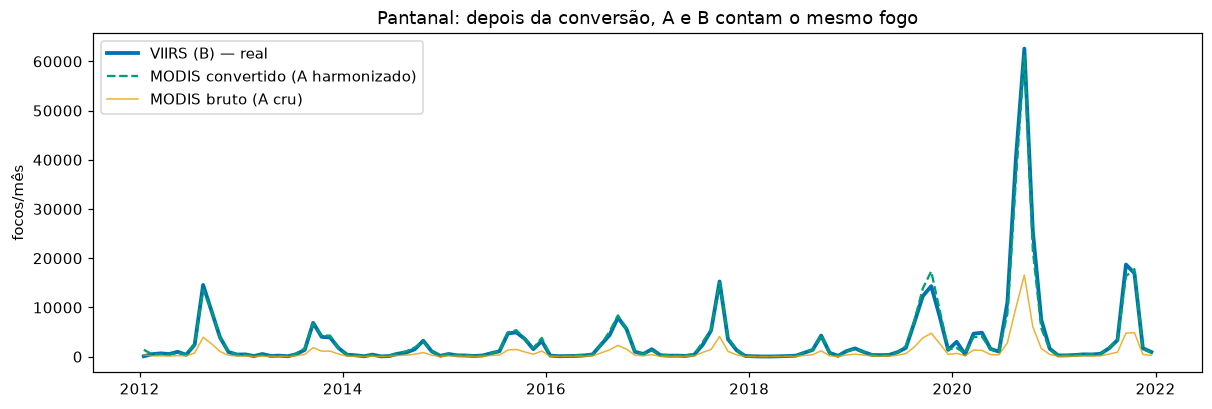

In [4]:
r = regiao('Pantanal').reset_index(); r['t'] = r.ano + (r.mes - .5) / 12
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(r.t, r.viirs, c=COR['VIIRS'], lw=2.5, label='VIIRS (B) — real')
ax.plot(r.t, r.modis_convertido, c=COR['CONV'], lw=1.5, ls='--', label='MODIS convertido (A harmonizado)')
ax.plot(r.t, r.modis_bruto, c=COR['MODIS'], lw=1, alpha=.8, label='MODIS bruto (A cru)')
ax.set_ylabel('focos/mês'); ax.legend(); ax.set_title('Pantanal: depois da conversão, A e B contam o mesmo fogo')
fig.savefig(REP / 'prova_pantanal.png', bbox_inches='tight')
anual = r.groupby('ano')[['modis_bruto', 'modis_convertido', 'viirs']].sum().round(0)
anual['diferença A×B'] = (anual.modis_convertido / anual.viirs - 1).map('{:+.1%}'.format); anual

## 3. Em todo o Brasil: quantas vezes A e B "dão o mesmo número"?
Dividimos o Brasil em **quadrados de 2° × 2° (~220 km)**, o tamanho típico de uma área que um gestor seleciona, e comparamos **todos os meses** de 2012–2021.
Contamos só região × mês com fogo relevante (VIIRS ≥ 100 focos no mês).

In [5]:
def quadros(df, lado):
    d = df.assign(qy=(df.lat // lado).astype(int), qx=(df.lon // lado).astype(int))
    return d.groupby(['qy', 'qx', 'ano', 'mes'])[['modis_bruto', 'modis_convertido', 'viirs']].sum().reset_index()
res = []
for lado, nome in [(1, '1° (~110 km)'), (2, '2° (~220 km)'), (5, '5° (~550 km)')]:
    q = quadros(cm, lado); q = q[q.viirs >= 100]
    dif_conv = (q.modis_convertido / q.viirs - 1).abs(); dif_bruto = (q.modis_bruto / q.viirs - 1).abs()
    res.append({'tamanho da região': nome, 'região×mês': len(q),
                'MODIS cru: diferença mediana': f'{dif_bruto.median():.0%}',
                'convertido: diferença mediana': f'{dif_conv.median():.0%}',
                'convertido: dentro de ±10%': f'{(dif_conv <= .10).mean():.0%}',
                'convertido: dentro de ±20%': f'{(dif_conv <= .20).mean():.0%}',
                'convertido: dentro de ±30%': f'{(dif_conv <= .30).mean():.0%}',
                'correlação': round(np.corrcoef(q.modis_convertido, q.viirs)[0, 1], 3)})
    if lado == 2: q2 = q
tab_regioes = pd.DataFrame(res); tab_regioes

,tamanho da região,região×mês,MODIS cru: diferença mediana,convertido: diferença mediana,convertido: dentro de ±10%,convertido: dentro de ±20%,convertido: dentro de ±30%,correlação
0,1° (~110 km),19466,74%,16%,33%,60%,77%,0.984
1,2° (~220 km),10601,74%,14%,39%,66%,82%,0.992
2,5° (~550 km),3541,74%,11%,47%,72%,85%,0.996


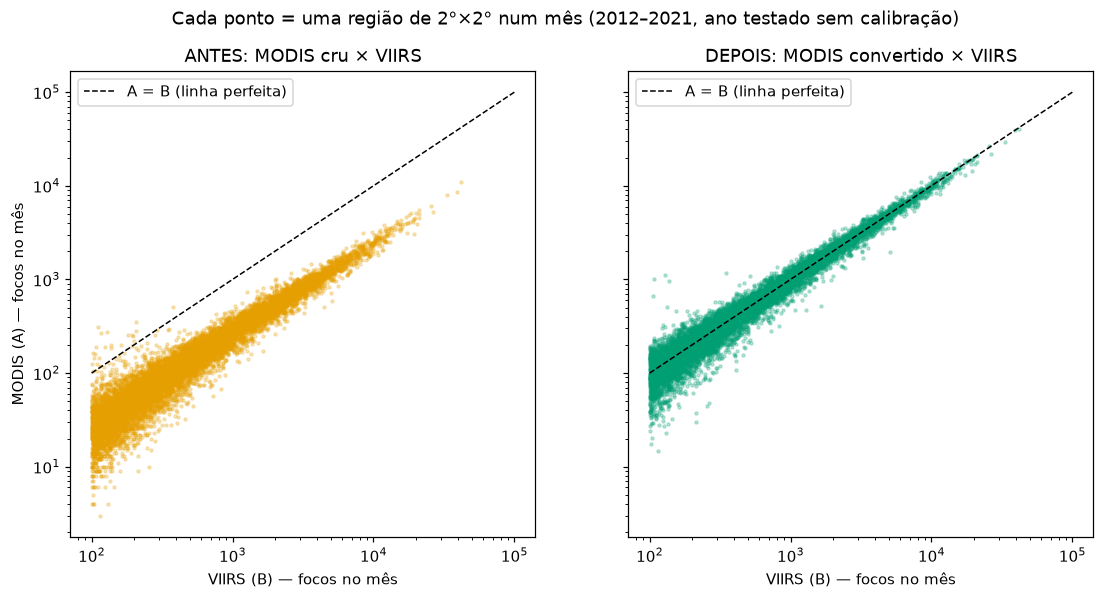

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
for a, col, tit, cor in [(ax[0], 'modis_bruto', 'ANTES: MODIS cru × VIIRS', COR['MODIS']),
                         (ax[1], 'modis_convertido', 'DEPOIS: MODIS convertido × VIIRS', COR['CONV'])]:
    a.scatter(q2.viirs, q2[col], s=4, alpha=.25, color=cor)
    x = np.logspace(2, 5); a.plot(x, x, 'k--', lw=1, label='A = B (linha perfeita)')
    a.set_xscale('log'); a.set_yscale('log'); a.set_xlabel('VIIRS (B) — focos no mês'); a.set_title(tit); a.legend()
ax[0].set_ylabel('MODIS (A) — focos no mês')
fig.suptitle('Cada ponto = uma região de 2°×2° num mês (2012–2021, ano testado sem calibração)')
fig.savefig(REP / 'prova_antes_depois.png', bbox_inches='tight')

## 4. A régua natural: dois VIIRS idênticos também não dão o mesmo número exato
S-NPP e NOAA-20 carregam **o mesmo instrumento VIIRS**, passam com ~50 min de diferença. Se até eles diferem um pouco, essa é a diferença **natural** (o fogo muda em 50 min, nuvens, ângulo de visada). Comparamos na mesma grade de 2°, 2018–2021.

In [7]:
con = duckdb.connect()
sql = lambda src: f'''SELECT floor(latitude/0.25)*0.25 lat, floor(longitude/0.25)*0.25 lon, year(CAST(acq_date AS DATE)) ano, month(CAST(acq_date AS DATE)) mes, count(*) n
 FROM {src} p ANTI JOIN '{(PROC / "static_mask.parquet").as_posix()}' m ON floor(p.latitude/0.02)::INT = m.fy AND floor(p.longitude/0.02)::INT = m.fx
 WHERE confidence IN ('n','h') AND year(CAST(acq_date AS DATE)) BETWEEN 2018 AND 2021 GROUP BY ALL'''
n20_arq = sorted((RAW / 'noaa20').glob('*.parquet'))
if n20_arq:
    s = con.execute(sql(f"read_parquet('{RAW.as_posix()}/viirs-snpp_*.parquet')")).df()
    n = con.execute(sql(f"read_parquet('{RAW.as_posix()}/noaa20/*.parquet')")).df()
    d = s.merge(n, on=['lat', 'lon', 'ano', 'mes'], how='outer', suffixes=('_snpp', '_n20')).fillna(0)
    d = d.assign(qy=(d.lat // 2).astype(int), qx=(d.lon // 2).astype(int)).groupby(['qy', 'qx', 'ano', 'mes'])[['n_snpp', 'n_n20']].sum()
    escala = d.n_snpp.sum() / d.n_n20.sum(); d = d[d.n_snpp >= 100]
    dv = (d.n_n20 * escala / d.n_snpp - 1).abs()
    teto = {'dentro de ±10%': f'{(dv <= .10).mean():.0%}', 'dentro de ±20%': f'{(dv <= .20).mean():.0%}',
            'diferença mediana': f'{dv.median():.0%}', 'correlação': round(np.corrcoef(d.n_n20, d.n_snpp)[0, 1], 3)}
    c2 = q2[q2.ano >= 2018]; dc = (c2.modis_convertido / c2.viirs - 1).abs()
    comp = pd.DataFrame({'NOAA-20 × S-NPP (dois VIIRS iguais)': teto,
                         'MODIS convertido × S-NPP (2018–2021)': {'dentro de ±10%': f'{(dc <= .10).mean():.0%}', 'dentro de ±20%': f'{(dc <= .20).mean():.0%}',
                                                                  'diferença mediana': f'{dc.median():.0%}', 'correlação': round(np.corrcoef(c2.modis_convertido, c2.viirs)[0, 1], 3)}})
    display(comp)
else:
    teto, comp = None, None; print('NOAA-20 não baixado (data/raw/noaa20/). Pule esta seção.')

,NOAA-20 × S-NPP (dois VIIRS iguais),MODIS convertido × S-NPP (2018–2021)
dentro de ±10%,60%,39%
dentro de ±20%,85%,66%
diferença mediana,8%,13%
correlação,0.996,0.991


## 5. Concordância por escala de tempo
O mesmo método, olhado em mês, trimestre e ano (região de 2°). Quanto mais tempo somado, menos o acaso de um dia de passagem pesa.

In [8]:
q2t = quadros(cm, 2)
escalas = []
for nome, chave, minimo in [('mês', q2t.mes, 100), ('trimestre', (q2t.mes - 1) // 3, 300), ('ano', 0, 300)]:
    a = q2t.assign(per=chave).groupby(['qy', 'qx', 'ano', 'per'])[['modis_convertido', 'viirs']].sum()
    a = a[a.viirs >= minimo]; d = (a.modis_convertido / a.viirs - 1).abs()
    escalas.append({'escala': nome, 'mínimo de focos VIIRS': minimo, 'casos': len(a), 'dentro de ±10%': f'{(d <= .1).mean():.0%}',
                    'dentro de ±20%': f'{(d <= .2).mean():.0%}', 'diferença mediana': f'{d.median():.1%}'})
mv = q2t.groupby(['qy', 'qx', 'ano', 'mes'])[['modis_convertido', 'viirs']].sum()
for lim in [300, 1000]:
    s = mv[mv.viirs >= lim]; d = (s.modis_convertido / s.viirs - 1).abs()
    escalas.append({'escala': f'mês com ≥ {lim} focos', 'mínimo de focos VIIRS': lim, 'casos': len(s), 'dentro de ±10%': f'{(d <= .1).mean():.0%}',
                    'dentro de ±20%': f'{(d <= .2).mean():.0%}', 'diferença mediana': f'{d.median():.1%}'})
tab_escalas = pd.DataFrame(escalas)
nac = cm.groupby(['ano', 'mes'])[['modis_convertido', 'viirs']].sum()
nac_an = nac.groupby(level=0).sum()
nacional = {'correlacao_mensal': round(np.corrcoef(nac.modis_convertido, nac.viirs)[0, 1], 4),
            'erro_anual_medio_abs': round(float((nac_an.modis_convertido / nac_an.viirs - 1).abs().mean()), 4)}
print('Brasil (validação deixando o ano de fora):', nacional); tab_escalas

Brasil (validação deixando o ano de fora): {'correlacao_mensal': np.float64(0.998), 'erro_anual_medio_abs': 0.0159}


,escala,mínimo de focos VIIRS,casos,dentro de ±10%,dentro de ±20%,diferença mediana
0,mês,100,10601,39%,66%,13.5%
1,trimestre,300,4016,54%,82%,9.1%
2,ano,300,1829,68%,92%,6.3%
3,mês com ≥ 300 focos,300,6278,48%,77%,10.6%
4,mês com ≥ 1000 focos,1000,2856,57%,85%,8.5%


## 6. Faixa de incerteza calibrada
Para cada região × mês, o app pode mostrar uma faixa em volta do número convertido. A largura vem dos erros dos **outros** anos (o ano testado nunca entra), separada pela quantidade de focos MODIS: com pouco fogo, a faixa é mais larga.

In [9]:
ev = q2.copy()   # região 2° × mês com VIIRS >= 100
ev['r'] = np.log((ev.viirs + .5) / (ev.modis_convertido + .5))
ev['faixa_modis'] = pd.cut(ev.modis_bruto, [-1, 20, 50, 150, 500, 1e9], labels=['≤20', '21–50', '51–150', '151–500', '>500'])
cob = [];
for y in sorted(ev.ano.unique()):
    tr, te = ev[ev.ano != y], ev[ev.ano == y]
    qs = tr.groupby('faixa_modis', observed=True).r.quantile([.05, .95, .10, .90]).unstack()
    t = te.join(qs, on='faixa_modis')
    cob.append(pd.DataFrame({'in90': t.r.between(t[.05], t[.95]), 'in80': t.r.between(t[.10], t[.90]), 'faixa_modis': t.faixa_modis}))
cob = pd.concat(cob)
largura = ev.groupby('faixa_modis', observed=True).r.quantile([.05, .95]).unstack()
largura = pd.DataFrame({'focos MODIS no mês': largura.index.astype(str),
                        'faixa de 90%: de': (np.exp(largura[.05]) - 1).map('{:+.0%}'.format).values,
                        'até': (np.exp(largura[.95]) - 1).map('{:+.0%}'.format).values})
faixa = {'cobertura_90_nominal': round(float(cob.in90.mean()), 3), 'cobertura_80_nominal': round(float(cob.in80.mean()), 3)}
print(f"Cobertura real da faixa de 90%: {faixa['cobertura_90_nominal']:.1%} | da faixa de 80%: {faixa['cobertura_80_nominal']:.1%}")
largura

Cobertura real da faixa de 90%: 89.9% | da faixa de 80%: 79.7%


,focos MODIS no mês,faixa de 90%: de,até
0,≤20,+6%,+229%
1,21–50,-28%,+81%
2,51–150,-34%,+44%
3,151–500,-25%,+31%
4,>500,-19%,+21%


**Leitura:** a faixa de 90% acerta ~90% das vezes (é calibrada). Ela é larga quando o MODIS viu pouco fogo e estreita quando viu muito. **Para o app:** mostrar "valor convertido (faixa de 90%: de X a Y)" nos anos antes de 2012, usando a tabela acima conforme a quantidade de focos MODIS.

## 7. Ideias testadas no debate e rejeitadas
Três agentes (Físico, Estatístico e Avaliador) propuseram métodos para subir a concordância; os escolhidos foram testados com as regras fixadas antes (região 2° × mês, VIIRS ≥ 100, ano deixado de fora). Código: `notebooks/exp_debate_metodos.py`.

| Ideia | Resultado | Decisão |
|---|---|---|
| Corrigir o fator de cada mês com covariáveis do MODIS (P90 do FRP, aglomeração, anomalia Terra/Aqua, fração noturna) | ±20%: 65,9% → 65,4%; melhorou em 1 de 10 anos; igual ao controle com covariáveis embaralhadas | rejeitada |
| "O erro restante é só ruído de contagem" | simulação com k perfeito daria 93,6% dentro de ±20%; o erro real é maior → o fator varia de verdade de ano para ano | hipótese rejeitada |
| Faixa de incerteza calibrada | cobre 89,9% (90% nominal) | **adotada** (seção 6) |
| LightGBM; peso pelo tamanho do pixel | risco de sobreajuste com 10 anos; exigiria novo download para +1–2 pontos | não testadas |
| Teste final 2022–2025 (fora da calibração) | 53% dentro de ±20%, diferença mediana 18% — efeito da deriva orbital do MODIS; o produto usa VIIRS real nesses anos | registrado |

**Conclusão:** 90–100% por região × mês não é alcançável (dois VIIRS idênticos ficam em 85%). Na escala anual o método chega a ~92% dentro de ±20%, e a faixa de incerteza é honesta (acerta 90%).

## 8. Salvar as métricas da prova (para o app e a apresentação)

In [10]:
mf = REP / 'metrics.json'
m = json.loads(mf.read_text(encoding='utf-8')) if mf.exists() else {}
m['prova_harmonizacao'] = {
    'descricao': 'Mesma região e mesmo mês: MODIS convertido (fator calculado sem o ano testado) × VIIRS real, 2012–2021, região×mês com VIIRS >= 100 focos.',
    'por_tamanho_regiao': tab_regioes.to_dict(orient='records'),
    'exemplos_pico_2020': pd.DataFrame(linhas, columns=['regiao', 'mes', 'modis_bruto', 'modis_convertido', 'viirs', 'diferenca']).to_dict(orient='records'),
    'referencia_noaa20_x_snpp_2deg': teto,
    'por_escala_de_tempo_2deg': tab_escalas.to_dict(orient='records'),
    'nacional_loyo_metodo_final': nacional,
    'faixa_incerteza': {**faixa, 'largura_por_focos_modis': largura.to_dict(orient='records'),
                        'uso': 'pre-2012: mostrar convertido com faixa de 90% conforme focos MODIS da regiao no mes'},
    'debate_metodos': {'covariaveis_modis': 'rejeitada (65,9% -> 65,4%; 1 de 10 anos; igual ao controle embaralhado)',
                       'teto_binomial_simulado_pct20': 0.936, 'teste_final_2022_2025_pct20': 0.533,
                       'script': 'notebooks/exp_debate_metodos.py'}}
m['nota'] = 'A secao loyo_2012_2021 (notebook 05) usa a versao 1 do metodo (bloco 5 graus, media Terra/Aqua). O metodo final esta em prova_harmonizacao (notebook 07).'
mf.write_text(json.dumps(m, ensure_ascii=False, indent=2), encoding='utf-8'); print('metrics.json atualizado')

metrics.json atualizado
